# Autoencoder Architecture

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os

# Define the path to the zip file and the extraction directory
zip_file_path = '/content/drive/MyDrive/UCSDped1.zip'
extract_path = '/content/UCSD_Anomaly'

# Extract the zip file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed.")

Extraction completed.


In [3]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import roc_auc_score, roc_curve
from tqdm import tqdm
import copy

In [17]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class UCSDDataset(Dataset):
    def __init__(self, root_dir, transform=None, mode='train'):
        self.root_dir = root_dir
        self.transform = transform
        self.mode = mode
        self.frames = []
        self.labels = []
        self.load_frames()

    def load_frames(self):
        if self.mode == 'train':
            normal_path = os.path.join(self.root_dir, 'Train', 'Normal')
            anomaly_path = os.path.join(self.root_dir, 'Train', 'Anomaly')

            self.load_from_path(normal_path, label=0)
            self.load_from_path(anomaly_path, label=1)

        elif self.mode == 'test':
            normal_path = os.path.join(self.root_dir, 'Test', 'Normal')
            anomaly_path = os.path.join(self.root_dir, 'Test', 'Anomaly')

            self.load_from_path(normal_path, label=0)
            self.load_from_path(anomaly_path, label=1, include_gt=True)

    def load_from_path(self, base_path, label, include_gt=False):
        for root, dirs, files in os.walk(base_path):
            for folder in dirs:
                folder_path = os.path.join(root, folder)
                if label == 1 and include_gt:
                    gt_folder = os.path.join(self.root_dir, 'Test', 'Anomaly', f"{folder}_gt")
                    if os.path.exists(gt_folder):
                        gt_frames = set(os.listdir(gt_folder))  # Use set for faster lookup
                    else:
                        gt_frames = set()
                else:
                    gt_frames = set()

                for frame_name in os.listdir(folder_path):
                    if frame_name.endswith('.tif'):
                        frame_path = os.path.join(folder_path, frame_name)
                        self.frames.append(frame_path)
                        if frame_name[:-4] + '.bmp' in gt_frames:
                            self.labels.append(1)
                        else:
                            self.labels.append(0)

        print(f"Loaded {len(self.frames)} frames from {base_path}")

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, idx):
        frame_path = self.frames[idx]
        try:
            image = Image.open(frame_path).convert("RGB")
        except Exception as e:
            print(f"Error loading image: {frame_path}, Error: {str(e)}")
            # Return a placeholder image and a label indicating error
            image = Image.fromarray(torch.zeros(3, 128, 128).numpy().astype('uint8').transpose((1, 2, 0)))

        if self.transform:
            image = self.transform(image)

        return image, self.labels[idx]

# Example usage
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomResizedCrop((128, 128), scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.Lambda(lambda x: x + 0.01 * torch.randn_like(x))  # Adding Gaussian noise
])

train_dataset = UCSDDataset('/content/UCSD_Anomaly/UCSDped1/', transform=transform, mode='train')
test_dataset = UCSDDataset('/content/UCSD_Anomaly/UCSDped1/', transform=transform, mode='test')

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0, pin_memory=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0, pin_memory=False)

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of testing samples: {len(test_dataset)}")


Loaded 4400 frames from /content/UCSD_Anomaly/UCSDped1/Train/Normal
Loaded 8000 frames from /content/UCSD_Anomaly/UCSDped1/Train/Anomaly
Loaded 2400 frames from /content/UCSD_Anomaly/UCSDped1/Test/Normal
Loaded 6000 frames from /content/UCSD_Anomaly/UCSDped1/Test/Anomaly
Number of training samples: 8000
Number of testing samples: 6000


In [10]:
import torch
import torch.nn as nn

class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super(SEBlock, self).__init__()
        self.fc1 = nn.Conv2d(channels, channels // reduction, kernel_size=1)
        self.fc2 = nn.Conv2d(channels // reduction, channels, kernel_size=1)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        batch, channel, _, _ = x.size()
        y = torch.mean(x, (2, 3), keepdim=True)
        y = self.relu(self.fc1(y))
        y = self.sigmoid(self.fc2(y))
        return x * y

In [11]:
import torch.nn.functional as F

class UNetSE(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, init_features=32):
        super(UNetSE, self).__init__()
        features = init_features

        self.encoder1 = UNetSE._block(in_channels, features, name="enc1")
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder2 = UNetSE._block(features, features * 2, name="enc2")
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder3 = UNetSE._block(features * 2, features * 4, name="enc3")
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder4 = UNetSE._block(features * 4, features * 8, name="enc4")
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.bottleneck = UNetSE._block(features * 8, features * 16, name="bottleneck")

        self.se1 = SEBlock(features)
        self.se2 = SEBlock(features * 2)
        self.se3 = SEBlock(features * 4)
        self.se4 = SEBlock(features * 8)
        self.se_bottleneck = SEBlock(features * 16)

        self.upconv4 = nn.ConvTranspose2d(
            features * 16, features * 8, kernel_size=2, stride=2
        )
        self.decoder4 = UNetSE._block((features * 8) * 2, features * 8, name="dec4")
        self.upconv3 = nn.ConvTranspose2d(
            features * 8, features * 4, kernel_size=2, stride=2
        )
        self.decoder3 = UNetSE._block((features * 4) * 2, features * 4, name="dec3")
        self.upconv2 = nn.ConvTranspose2d(
            features * 4, features * 2, kernel_size=2, stride=2
        )
        self.decoder2 = UNetSE._block((features * 2) * 2, features * 2, name="dec2")
        self.upconv1 = nn.ConvTranspose2d(
            features * 2, features, kernel_size=2, stride=2
        )
        self.decoder1 = UNetSE._block(features * 2, features, name="dec1")

        self.conv = nn.Conv2d(
            in_channels=features, out_channels=out_channels, kernel_size=1
        )

    def forward(self, x):
        enc1 = self.encoder1(x)
        enc1 = self.se1(enc1)
        enc2 = self.encoder2(self.pool1(enc1))
        enc2 = self.se2(enc2)
        enc3 = self.encoder3(self.pool2(enc2))
        enc3 = self.se3(enc3)
        enc4 = self.encoder4(self.pool3(enc3))
        enc4 = self.se4(enc4)
        bottleneck = self.bottleneck(self.pool4(enc4))
        bottleneck = self.se_bottleneck(bottleneck)

        dec4 = self.upconv4(bottleneck)
        dec4 = torch.cat((dec4, enc4), dim=1)
        dec4 = self.decoder4(dec4)
        dec3 = self.upconv3(dec4)
        dec3 = torch.cat((dec3, enc3), dim=1)
        dec3 = self.decoder3(dec3)
        dec2 = self.upconv2(dec3)
        dec2 = torch.cat((dec2, enc2), dim=1)
        dec2 = self.decoder2(dec2)
        dec1 = self.upconv1(dec2)
        dec1 = torch.cat((dec1, enc1), dim=1)
        dec1 = self.decoder1(dec1)
        return self.conv(dec1)

    @staticmethod
    def _block(in_channels, features, name):
        return nn.Sequential(
            OrderedDict(
                [
                    (name + "conv1", nn.Conv2d(in_channels, features, kernel_size=3, padding=1, bias=False)),
                    (name + "norm1", nn.BatchNorm2d(features)),
                    (name + "relu1", nn.ReLU(inplace=True)),
                    (name + "conv2", nn.Conv2d(features, features, kernel_size=3, padding=1, bias=False)),
                    (name + "norm2", nn.BatchNorm2d(features)),
                    (name + "relu2", nn.ReLU(inplace=True)),
                ]
            )
        )


Epoch 1/20:   8%|▊         | 21/250 [00:06<01:15,  3.05it/s]

Error loading image: /content/UCSD_Anomaly/UCSDped1/Train/Anomaly/Test017/142.tif, Error: -2


Epoch 1/20: 100%|██████████| 250/250 [01:14<00:00,  3.36it/s]


Epoch 1/20, Loss: 0.4368
Saving model with lowest loss (0.4368) at epoch 1


Epoch 2/20:  72%|███████▏  | 181/250 [00:54<00:21,  3.25it/s]

Error loading image: /content/UCSD_Anomaly/UCSDped1/Train/Anomaly/Test017/142.tif, Error: -2


... (70 outputs left out)

Epoch 20/20:  29%|██▉       | 73/250 [00:22<00:52,  3.35it/s]

Error loading image: /content/UCSD_Anomaly/UCSDped1/Train/Anomaly/Test017/142.tif, Error: -2


Epoch 20/20: 100%|██████████| 250/250 [01:15<00:00,  3.32it/s]


Epoch 20/20, Loss: 0.0024


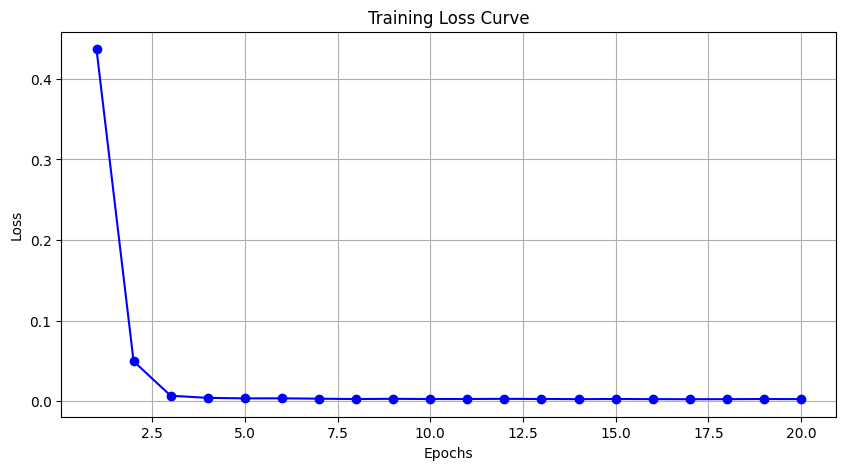

In [19]:
from collections import OrderedDict
from torch.optim.lr_scheduler import CyclicLR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNetSE().to(device)

criterion = nn.MSELoss()
optimizer = optim.AdamW(model.parameters(), lr=0.0001, weight_decay=1e-5)
scheduler = CyclicLR(optimizer, base_lr=1e-6, max_lr=1e-3, step_size_up=2000, mode='triangular')

# Early stopping parameters
patience = 10
best_loss = float('inf')
trigger_times = 0

num_epochs = 20
train_losses = []

# Ensure the checkpoint directory exists
checkpoint_dir = '/content/drive/My Drive/Your_Checkpoint_Folder/'
os.makedirs(checkpoint_dir, exist_ok=True)

# Define where to save model checkpoints
checkpoint_path = '/content/drive/My Drive/Your_Checkpoint_Folder/model_checkpoint.pth'
best_model_path = '/content/drive/My Drive/Your_Checkpoint_Folder/best_model.pth'

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for data in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        inputs, _ = data  # Unpack the batch
        inputs = inputs.to(device)  # Move inputs to device
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()
        scheduler.step()
        train_loss += loss.item() * inputs.size(0)

    train_loss = train_loss / len(train_loader.dataset)
    train_losses.append(train_loss)
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {train_loss:.4f}")

    # Save model checkpoint
    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'train_loss': train_loss,
    }, checkpoint_path)

    # Save best model based on lowest loss
    if train_loss < best_loss:
        best_loss = train_loss
        trigger_times = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"Saving model with lowest loss ({best_loss:.4f}) at epoch {epoch + 1}")
    else:
        trigger_times += 1
        if trigger_times >= patience:
            print("Early stopping!")
            break

# Plotting the training loss curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', linestyle='-', color='b')
plt.title('Training Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.show()


In [21]:
from PIL import Image
import numpy as np
from sklearn.metrics import roc_auc_score, roc_curve

# Assuming 'best_model_path' contains the path to your best model checkpoint
best_model_path = '/content/drive/My Drive/Your_Checkpoint_Folder/best_model.pth'

# Load the best model
best_model = UNetSE().to(device)
best_model.load_state_dict(torch.load(best_model_path))
best_model.eval()

# Compute reconstruction errors on the test set using the best model
def compute_reconstruction_error(model, data_loader):
    model.eval()
    criterion = nn.MSELoss()  # Define your criterion here if not already defined globally
    errors = []
    with torch.no_grad():
        for data in data_loader:
            inputs, _ = data  # Unpack the batch
            inputs = inputs.to(device)  # Move inputs to device
            outputs = model(inputs)
            loss = criterion(outputs, inputs)
            errors.extend(loss.cpu().numpy().flatten())
    return errors

# Compute reconstruction errors on the test set using the best model
test_errors = compute_reconstruction_error(best_model, test_loader)

# Assuming ground truth labels for anomalies (0 for normal, 1 for anomaly)
# For this example, we will create a dummy ground truth labels array.
# Replace this with actual labels if available.
test_labels = np.zeros(len(test_errors))
# Mark some frames as anomalous for demonstration purposes
test_labels[len(test_labels) // 2:] = 1

# Calculate ROC-AUC
roc_auc = roc_auc_score(test_labels, test_errors)
print(f"ROC-AUC: {roc_auc:.4f}")

# Calculate EER
fpr, tpr, thresholds = roc_curve(test_labels, test_errors)
fnr = 1 - tpr
eer_threshold = thresholds[np.nanargmin(np.absolute(fnr - fpr))]
eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
print(f"EER: {eer:.4f}")


ROC-AUC: 0.6919
EER: 0.3191


In [ ]:
threshold = np.percentile(reconstruction_errors, 95)  # Example: 95th percentile

anomalies = reconstruction_errors > threshold